# The grid roof, step by step

An 18 × 12 m roof, 600 mm thick, on a 6 m beam grid, made to read as eroded rock. Each step below is one
group of components on a Grasshopper canvas, written as code:

| Canvas | Here |
|---|---|
| number sliders | `roof.Brief(...)` |
| referenced curves and points | `drawing.json` |
| a group of components | one call to `grid_roof` |
| wires | each step's outputs feed the next |
| viewport | `roof.preview` plots |
| `run` toggle | `RUN_ALL`, `EXPORT`, `PRINT` |

`compas_vol` is the general library; its `compas_vol.nodes` are the Grasshopper components. `grid_roof`, next
to this notebook, holds the roof's steps, built from those nodes. `build.py` runs the same steps as a batch.

```bash
uv sync --extra notebook && uv run jupyter lab walkthrough.ipynb
```

Units are millimetres. Most steps end with **Try**: one change, and what to look for. Change a number, then rerun from
the step that reads it down.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

import grid_roof as roof
from compas_vol import nodes
from compas_vol.assembly import Seams
from compas_vol.meshing import is_watertight, write_stl

plt.rcParams.update({"figure.dpi": 80, "font.size": 9})

## Step 0 · Environment
*Canvas: **Volumetric Info***

In [2]:
print(nodes.info(None)[0])

compas_vol 0.2.0 on Python 3.13.14
context      : headless
scipy        : yes  [meshing] grid filtering, labelling and interpolation
skimage      : yes  [meshing] marching-cubes iso-surfacing
skfmm        : yes  [processes] redistancing, which every process step depends on
compas_viewer: no   [viewer] the standalone OpenGL viewer
matplotlib   : yes  [examples] the field slice inspector used by the examples
Rhino        : no   [host] Rhino geometry; it exists only inside Rhino or Grasshopper


## Step 1 · The brief
*Canvas: number sliders*

Change a value and rerun from here down. Fields not set keep their defaults; `print(brief)` shows them all.

**Try:** `pore=400`, or `1200`, then rerun from Step 6.

In [3]:
brief = roof.Brief(
    length=18000, width=12000, thickness=600,   # the roof
    grid_x=[0, 6000, 12000, 18000],             # beam centre lines; edge beams sit inboard
    grid_y=[0, 6000, 12000],
    beam=600, beam_depth=500,                   # beam width, and the depth every beam keeps     400-800, 400-600
    fall=1 / 60, relief=25,                     # deck falls to the drains; undulation           1/100-1/40, 0-40
    skin=120, pore=700,                         # solid deck over the pores; pore to pore        80-200, 300-1200
    fraction_deck=0.95, fraction_soffit=0.42,   # solid share under the deck, at the soffit
    opening_flare=260, planter_depth=350,       # light flares at the faces; planter soil depth
    panel=3000, clearance=10,                   # largest panel; joint gap
    min_feature=80,                             # thinnest wall that may survive
    voxel=40, halo=320,                         # 40 to look, 10-15 to make; margin each piece is weathered with
)
RUN_ALL = False                                 # build all 53 pieces (about two minutes at 40 mm)
EXPORT = False                                  # write STLs to OUT
PRINT = False                                   # build a printable sample in Step 15 (about three minutes)
OUT = "out"

## Step 2 · The drawing
*Canvas: Curve and Point parameters*

Light openings, planters and drains, in mm on the 18 × 12 m plan, origin at a corner.

**Try:** a fourth opening, `drawing.openings.append(roof.blob((16000, 1800), 500, seed=9))`, then rerun
from Step 4; Step 9 checks it. To draw your own: `docs/your-design.md`.

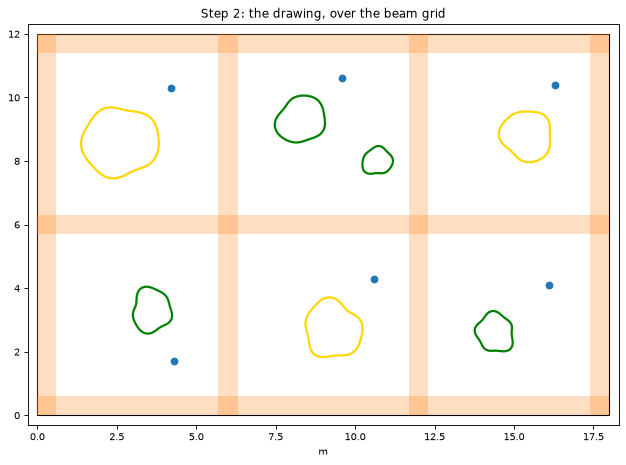

In [4]:
drawing = roof.Drawing.load("drawing.json")
beams = roof.beams(brief)
roof.preview.plan(brief, drawing, beams, title="Step 2: the drawing, over the beam grid");

## Step 3 · The beams
*`roof.beams` · Canvas: **Volumetric Box** × 7 → **Volumetric Boolean***

Every beam keeps `beam_depth` from the soffit through every later step. Each is a box centred on its grid line;
edge beams sit inboard. Negative distance is solid.

**Try:** `beam=400` in Step 1: narrower beams, and the pores come closer.

In [5]:
print("beams along X at", [(round(a), round(b)) for a, b in beams.xbands])
print("beams along Y at", [(round(a), round(b)) for a, b in beams.ybands])
print("inside a beam, 250 mm up:", round(beams.core.get_distance([6000, 3000, 250]), 1), "mm")

beams along X at [(0, 600), (5700, 6300), (11700, 12300), (17400, 18000)]
beams along Y at [(0, 600), (5700, 6300), (11400, 12000)]
inside a beam, 250 mm up: -250.0 mm


## Step 4 · Water
*`roof.water` · Canvas: no component yet*

Solved in plan over the whole roof. The deck falls to the drains; water is kept off the light openings and
soaks into the planters. Channels are sized by the area they drain and never cut below a beam.

**Try:** halve `channel_onset`: channels start sooner and branch more.

{'channel_length': 69650.0, 'deepest_cut': 141.10538930886185, 'widest': 447.18754454926403, 'outlets': 10, 'outlets_used': 10, 'largest_catchment': 41317500.0, 'stranded': 0, 'reverse_falls': 0}


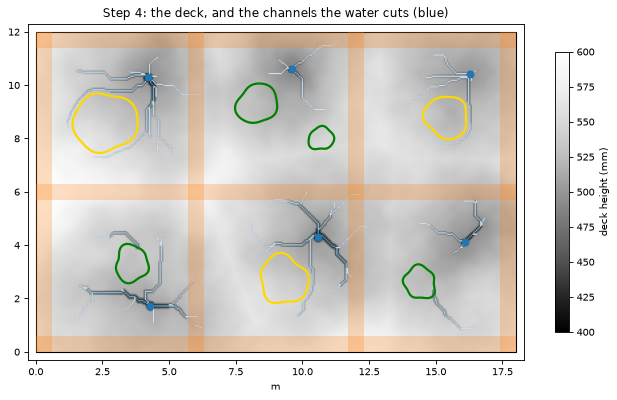

In [6]:
incision = roof.water(brief, drawing, beams)
print(incision.summary())
roof.preview.plan(brief, drawing, beams, incision, title="Step 4: the deck, and the channels the water cuts (blue)");

## Step 5 · Deck and slab
*`roof.slab` · Canvas: **Volumetric Box** → **Volumetric Boolean** (intersection)*

The worn deck becomes a solid, trimmed to the roof outline.

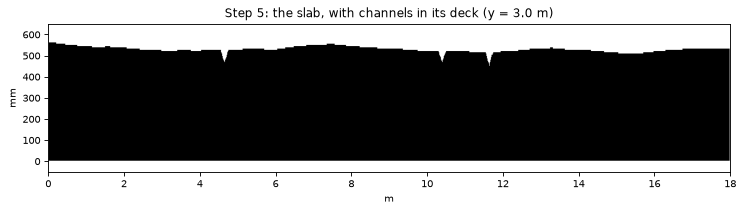

In [7]:
slab = roof.slab(brief, incision)
roof.preview.section(brief, slab.solid, 3000, title="Step 5: the slab, with channels in its deck");

## Step 6 · Porous soffit
*`roof.soffit` · Canvas: no component yet*

A foam below the deck: solid near the deck, open at the soffit, closing towards each beam. It is defined in world
coordinates, so pieces built separately share it.

**Try:** `fraction_soffit=0.6` for a denser soffit, or `skin=80` for a thinner deck.

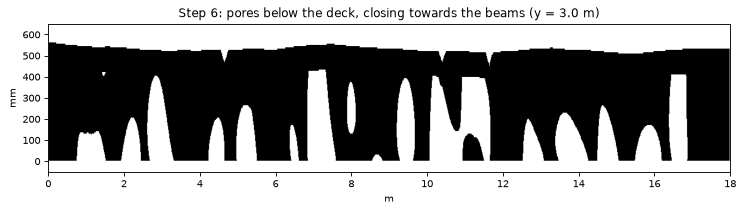

In [8]:
soffit = roof.soffit(brief, slab, beams)
roof.preview.section(brief, soffit.porous, 3000, title="Step 6: pores below the deck, closing towards the beams");

## Step 7 · Light and planters
*`roof.voids`, `roof.carve` · Canvas: **Volumetric Cylinder**, **Volumetric Boolean** (difference)*

Light openings flare towards both faces; planters are blind pockets; each drain gets an outlet bore.

**Try:** `opening_flare=0` for straight-sided openings.

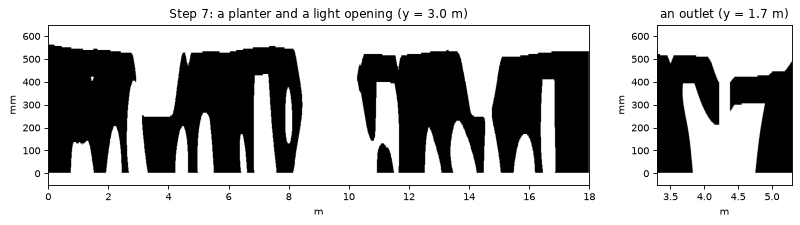

In [9]:
voids = roof.voids(brief, drawing, slab)
carved = roof.carve(soffit.porous, voids)
fig, axes = plt.subplots(1, 2, figsize=(12, 2.6), gridspec_kw={"width_ratios": [4, 1]})
roof.preview.section(brief, carved, 3000, ax=axes[0], title="Step 7: a planter and a light opening")
roof.preview.section(brief, carved, 1700, x_range=(3300, 5300), ax=axes[1], title="an outlet");

## Step 8 · What must stay
*`roof.keep`, `roof.design` · Canvas: **Volumetric Boolean** (union)*

The beams, the deck and each planter's wall and floor, outlined in orange. Every piece is weathered with them as a
constraint. `design.drawn` omits the foam; joints are placed against it.

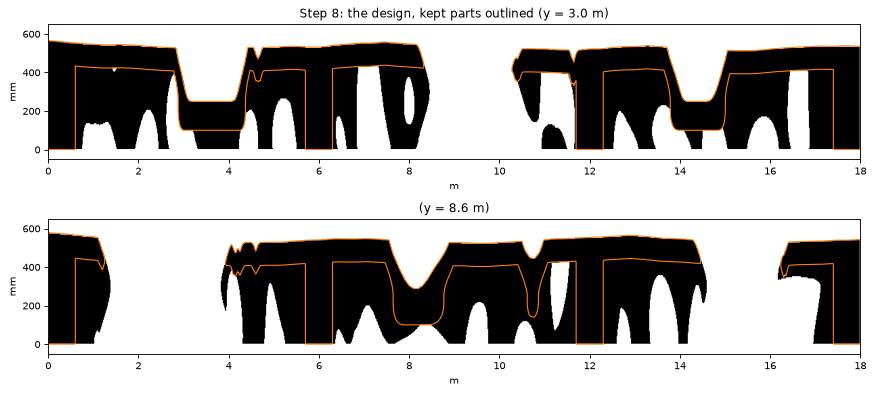

In [10]:
keep = roof.keep(brief, beams, slab, soffit, voids)
design = roof.design(slab, soffit, voids, keep)
fig, axes = plt.subplots(2, 1, figsize=(11, 5))
roof.preview.section(brief, design.roof, 3000, keep=keep, ax=axes[0], title="Step 8: the design, kept parts outlined")
roof.preview.section(brief, design.roof, 8600, keep=keep, ax=axes[1])
fig.tight_layout()

## Step 9 · Checks
*Canvas: panels*

Later steps only remove material outside what is kept, so these are lower bounds.

**Try:** draw an opening across a beam: its clear area falls short of the drawn one, because the beam is kept.

In [11]:
for n, aperture in enumerate(roof.clear_apertures(brief, drawing, design.roof)):
    print("opening {}: drawn {drawn:.2f} m2, clear line of sight {clear:.2f} m2".format(n, **aperture))
summary = incision.summary()
print("puddles in channel beds: {reverse_falls}, water with nowhere to go: {stranded}".format(**summary))

opening 0: drawn 4.15 m2, clear line of sight 4.26 m2
opening 1: drawn 2.55 m2, clear line of sight 2.69 m2
opening 2: drawn 2.02 m2, clear line of sight 2.11 m2
puddles in channel beds: 0, water with nowhere to go: 0


## Step 10 · Kit of parts
*`roof.kit` · Canvas: no component yet*

Nodes where beams cross, whole beams between them, panels no larger than `panel`, joints moved off openings
and planters. The cost line shows why the roof is never sampled whole.

**Try:** `panel=2000`: more, smaller panels, and a smaller largest piece.

53 pieces. At 12 mm: whole roof 1.4 GB per array, largest piece 78 MB


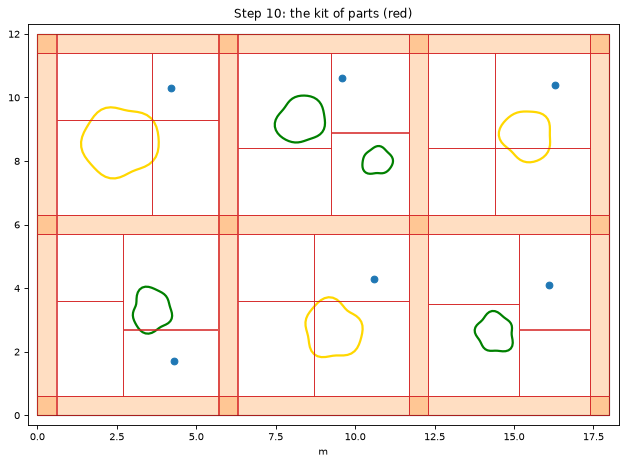

In [12]:
assembly = roof.kit(brief, design)
cost = assembly.cost(voxel=12.0, halo=brief.halo)
print("{} pieces. At 12 mm: whole roof {:.1f} GB per array, largest piece {:.0f} MB".format(
    len(assembly), cost["whole_model_bytes"] / 1e9, cost["per_piece_bytes"] / 1e6))
roof.preview.plan(brief, drawing, beams, pieces=assembly, title="Step 10: the kit of parts (red)");

## Step 11 · One piece, weathered
*`roof.weathering`, `Assembly.build` · Canvas: **Volumetric Pitting** → **Abrasion** → **Morphology***

`assembly.build` samples a piece with a halo, weathers it, cuts it back and adds its dowels. It returns the
finished field and the weathered field before the cut. The canvas components have no keep input yet; a Boolean
union with the keep after them gives the same guarantee.

**Try:** another piece, such as `"beam_x1_0_0"`, or a deeper `pit_depth` in Step 1.

In [13]:
weather = roof.weathering(brief, keep, slab)
piece = assembly.find("panel_0_1_00")                    # the bay with the large light opening
_, built, processed = next(assembly.build(weather, brief.voxel, brief.halo, pieces=[piece]))
print("{}: {:.0f} x {:.0f} mm; kept material missing: {:.1f} mm".format(
    piece.name, *piece.size[:2], processed.violation()["keep"]))

panel_0_1_00: 2990 x 2990 mm; kept material missing: 0.0 mm


## Step 12 · Inspect and mesh
*Canvas: **Volumetric Inspect**, **Volumetric Mesh***

The weathered field shows whether the design is makeable. The finished piece adds slivers where its box cuts a
pore, continued by the neighbour. Overhang lines assume printing upwards.

size           : 3040.0 x 3080.0 x 560.0 mm, 2128192 cm3
pieces         : 1
sealed cavities: 0
overhang       : 9% of the surface past 60 degrees
mid-air starts : 2 regions, 176.0 cm2
unsupported    : 13776.0 cm2 reaching past the layer below
wall thickness : 405.5 mm typical, 119.9 mm thinnest, 0.0% under 80.0 mm
verdict        : 2 problem(s)
  - 2 regions start in mid-air (176.0 cm2)
  - 13776.0 cm2 reaches past what the layer below can hold
  fixes: compas_vol.fabrication.keep_largest, drain_voids, make_self_supporting,
         compas_vol.processes.opened

finished piece: wall thickness : 190.0 mm typical, 9.8 mm thinnest, 12.6% under 80.0 mm
29,856 triangles, watertight: True


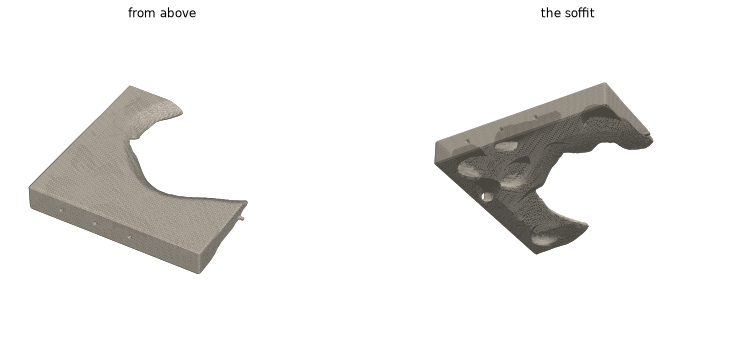

In [14]:
print(nodes.inspect(processed.cropped(piece.bounds).to_volume(), None, None, 60, brief.min_feature)[0])
finished = nodes.inspect(built.to_volume(), None, None, 60, brief.min_feature)[0]
print("\nfinished piece:", [line for line in finished.splitlines() if line.startswith("wall")][0])

vertices, faces = nodes.mesh(built.to_volume(), None, None, 0)
print("{:,} triangles, watertight: {}".format(len(faces), is_watertight(vertices, faces)))
fig = plt.figure(figsize=(12, 5))
roof.preview.meshes([(vertices, faces)], fig.add_subplot(1, 2, 1, projection="3d"), 40, -60, "from above")
roof.preview.meshes([(vertices, faces)], fig.add_subplot(1, 2, 2, projection="3d"), -35, -60, "the soffit");

## Step 13 · Piece by piece
*Canvas: `run` toggle*

One piece in memory at a time. `Seams` checks that neighbours meet. `RUN_ALL = False` builds one bay.

**Try:** `RUN_ALL = True` (about two minutes) and `EXPORT = True` to write every piece to `out/`.

panel_0_1_00    29,856 triangles, watertight True


panel_0_1_01    27,440 triangles, watertight True


panel_0_1_10    30,112 triangles, watertight True


panel_0_1_11    21,804 triangles, watertight True
seams: {'faces': 4, 'offset': 0.4109720816686462, 'disagreement': 0.0}


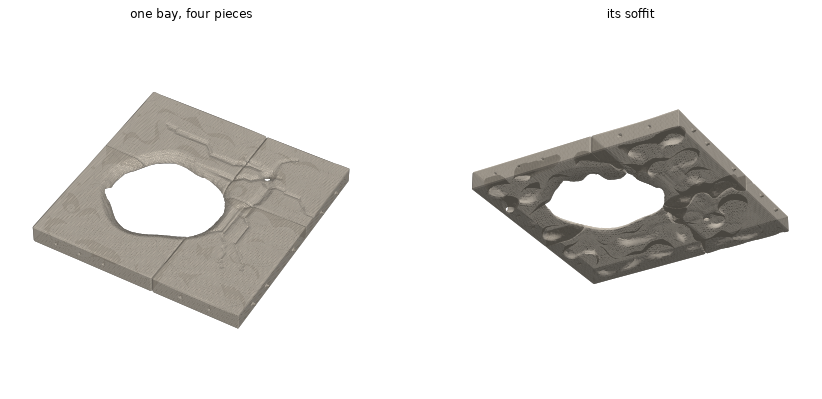

In [15]:
chosen = list(assembly) if RUN_ALL else [p for p in assembly if p.name.startswith("panel_0_1_")]
seams, meshes = Seams(assembly, brief.voxel), []
for piece, built, _ in assembly.build(weather, brief.voxel, brief.halo, pieces=chosen, seams=seams):
    vertices, faces = nodes.mesh(built.to_volume(), None, None, 0)
    print("{:<14} {:>7,} triangles, watertight {}".format(piece.name, len(faces), is_watertight(vertices, faces)))
    if EXPORT:
        write_stl("{}/{}.stl".format(OUT, piece.name), vertices, faces, name=piece.name)
    if piece.name.startswith("panel_0_1_"):
        meshes.append((vertices, faces))
print("seams:", seams.summary())

fig = plt.figure(figsize=(13, 6))
roof.preview.meshes(meshes, fig.add_subplot(1, 2, 1, projection="3d"), 45, -60, "one bay, four pieces")
roof.preview.meshes(meshes, fig.add_subplot(1, 2, 2, projection="3d"), -30, -60, "its soffit");

## Step 14 · Hand-off

The brief and the drawing are the whole design; `build.py` builds them at any resolution:

```bash
uv run python build.py --voxel 12 --out out
```

In [16]:
brief.save("brief.json")
print("saved brief.json; build.py reads it, with drawing.json")

saved brief.json; build.py reads it, with drawing.json


## Step 15 · A sample to print
*`roof.printing.sample` · Canvas: **Roof Print***

One piece at 1:20 for the Prusa: nothing thinner than 1.2 mm, pins with 0.2 mm of play, soffit on the plate,
checked as a slicer would. About three minutes for a panel. Then slice it: `docs/print.md`.

**Try:** `scale=25`, and compare the thinnest wall in the report.

In [17]:
import os

if PRINT:
    printable = roof.printing.sample(brief, design, weather, "panel_0_1_00", scale=20)   # printer="xl" for the XL
    print(printable.summary())
    os.makedirs("prints", exist_ok=True)
    write_stl("prints/panel_0_1_00-1to20.stl", printable.vertices, printable.faces)
else:
    print("PRINT is False: set it in Step 1 to build the sample here, or run")
    print("    uv run python print_sample.py panel_0_1_00")

PRINT is False: set it in Step 1 to build the sample here, or run
    uv run python print_sample.py panel_0_1_00


## On the canvas

The same workflow in Grasshopper, with the **Grid Roof** components (`docs/grasshopper.md`):

| Steps | Component |
|---|---|
| 1 · brief | **Roof Brief** |
| 2 · drawing | **Roof Drawing** |
| 3–10 · beams to kit | **Roof Design**, then **Volumetric Mesh** to see it |
| 11–12 · one piece | **Roof Piece** |
| 15 · a sample to print | **Roof Print** |

To take a single step out on its own, call it from a Python 3 **Script** component: `import grid_roof as roof`.